# COVID QA Retrieval Benchmark

**Owner:** Amaresh Hebbar, AnacodicAI Labs
**Dataset:** [anacodicai-labs/covidqa-bench](https://huggingface.co/datasets/anacodicai-labs/covidqa-bench)
**Scope:** scoring retrieval over the fixed production chunks (`chunks.jsonl`, 64,965 chunks, 512 token Docling HybridChunker). Re chunking the parsed papers is a separate task.

## What this notebook answers

1. **How good is retrieval?** Recall@k, Hit@k, Precision@k, MRR, nDCG@k and MAP@k for several retrievers, with 95% bootstrap confidence intervals.
2. **Is it stable when we ask the same questions again?** The full question set is run several times, and we measure whether the top k lists, the metrics and the per query outcomes change between runs.
3. **How many questions do we need?** We sample 50, 100, 250, 500, 1000 and all questions many times and watch how much the score moves. This tells us when a benchmark number is trustworthy.
4. **Where does it break?** Easy corpus (137 question papers) versus hard corpus (all 1,637 papers including 1,500 topic matched decoys), breakdowns by answer match type and gold chunk count, and concrete failure examples.

## Retrievers compared

| Name | What it is |
|---|---|
| `bm25` | Lexical baseline (bm25s, English stopwords) |
| `dense` | Sentence embedding model, exact cosine search (FAISS flat) |
| `dense_hnsw` | Same embeddings, approximate search (FAISS HNSW, rebuilt every run), the closest stand in for a production vector DB like Pinecone |
| `hybrid` | Reciprocal Rank Fusion of `bm25` and `dense` |

## Two relevance definitions

* **chunk_id**: a retrieved chunk is relevant if its id is in `gold_chunk_ids`. This is the official scoring for the fixed 512 token chunks.
* **text_match**: a retrieved chunk is relevant if it belongs to the gold paper and its text contains the normalized gold answer. This is the scoring the dataset card asks for when chunking changes, and it gives us a second opinion on the same runs.

Questions whose `gold_chunk_ids` is empty (the parse lost the answer, `match = none`) cannot be scored and are reported separately.

## 0. Setup

In [ ]:
%pip install -q bm25s faiss-cpu sentence-transformers huggingface_hub pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import sys
import json
import math
import time
import random
import hashlib
import platform
import unicodedata
from pathlib import Path
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

CONFIG = {
    "hf_repo": "anacodicai-labs/covidqa-bench",
    "questions_file": "gold/questions.jsonl",
    "chunks_file": "chunks.jsonl",
    "local_questions": os.environ.get("COVIDQA_QUESTIONS"),
    "local_chunks": os.environ.get("COVIDQA_CHUNKS"),
    "text_field": "embed_text",
    "settings": ["questions_only", "full_with_decoys"],
    "retrievers": ["bm25", "dense", "dense_hnsw", "hybrid"],
    "dense_model": "BAAI/bge-small-en-v1.5",
    "query_prefix": "Represent this sentence for searching relevant passages: ",
    "doc_prefix": "",
    "device": None,
    "batch_size": 64,
    "hnsw_m": 32,
    "hnsw_ef_search": 32,
    "rrf_k": 60,
    "rrf_depth": 100,
    "ks": [1, 3, 5, 10, 20],
    "primary_k": 10,
    "primary_metric": "ndcg",
    "repeat_runs": 5,
    "shuffle_each_run": True,
    "sample_sizes": [50, 100, 250, 500, 1000, None],
    "samples_per_size": 200,
    "bootstrap_iters": 2000,
    "margins": [0.05, 0.02, 0.01],
    "max_questions": None,
    "seed": 42,
    "cache_dir": "cache",
    "results_dir": "results",
}
CONFIG.update(json.loads(os.environ.get("BENCH_CONFIG", "{}")))

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
CACHE = Path(CONFIG["cache_dir"])
RESULTS = Path(CONFIG["results_dir"])
CACHE.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
KS = sorted(CONFIG["ks"])
PK = CONFIG["primary_k"]
PM = f'{CONFIG["primary_metric"]}@{PK}'
TOPK = max(KS)
DEPTH = max(TOPK, CONFIG["rrf_depth"])
NEEDS_DENSE = any(r in CONFIG["retrievers"] for r in ("dense", "dense_hnsw", "hybrid"))
NEEDS_BM25 = any(r in CONFIG["retrievers"] for r in ("bm25", "hybrid"))
print(json.dumps(CONFIG, indent=2))

{
  "hf_repo": "anacodicai-labs/covidqa-bench",
  "questions_file": "gold/questions.jsonl",
  "chunks_file": "chunks.jsonl",
  "local_questions": null,
  "local_chunks": null,
  "text_field": "embed_text",
  "settings": [
    "questions_only",
    "full_with_decoys"
  ],
  "retrievers": [
    "bm25",
    "dense",
    "dense_hnsw",
    "hybrid"
  ],
  "dense_model": "BAAI/bge-small-en-v1.5",
  "query_prefix": "Represent this sentence for searching relevant passages: ",
  "doc_prefix": "",
  "device": null,
  "batch_size": 64,
  "hnsw_m": 32,
  "hnsw_ef_search": 32,
  "rrf_k": 60,
  "rrf_depth": 100,
  "ks": [
    1,
    3,
    5,
    10,
    20
  ],
  "primary_k": 10,
  "primary_metric": "ndcg",
  "repeat_runs": 5,
  "shuffle_each_run": true,
  "sample_sizes": [
    50,
    100,
    250,
    500,
    1000,
    null
  ],
  "samples_per_size": 200,
  "bootstrap_iters": 2000,
  "margins": [
    0.05,
    0.02,
    0.01
  ],
  "max_questions": null,
  "seed": 42,
  "cache_dir": "cache",
  "

## 1. Load the benchmark

`gold/questions.jsonl` holds the 1,852 questions. `chunks.jsonl` holds the 64,965 production chunks for all 1,637 papers. Set `COVIDQA_QUESTIONS` and `COVIDQA_CHUNKS` to local paths if you already downloaded them; otherwise they are pulled from the Hub and cached.

`embed_text` is the contextualized chunk (section headings prepended), which is what the production pipeline embeds, so it is the default index field. Switch `text_field` to `text` to measure the effect of contextualization.

In [3]:
def resolve(local, remote):
    if local:
        return Path(local)
    from huggingface_hub import hf_hub_download
    return Path(hf_hub_download(CONFIG["hf_repo"], remote, repo_type="dataset"))


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def file_sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()[:16]


Q_PATH = resolve(CONFIG["local_questions"], CONFIG["questions_file"])
C_PATH = resolve(CONFIG["local_chunks"], CONFIG["chunks_file"])
questions_raw = read_jsonl(Q_PATH)
chunks_raw = read_jsonl(C_PATH)
DATA_HASH = {"questions": file_sha(Q_PATH), "chunks": file_sha(C_PATH)}
print(f"questions: {len(questions_raw):,}   chunks: {len(chunks_raw):,}")
print("question fields:", sorted(questions_raw[0].keys()))
print("chunk fields:   ", sorted(chunks_raw[0].keys()))
print("data hashes:    ", DATA_HASH)

/home/amareshhebbar/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


questions: 1,852   chunks: 64,965
question fields: ['gold_answer', 'gold_chunk_ids', 'id', 'match', 'paper_id', 'question']
chunk fields:    ['bib_provenance', 'caption', 'chunk_id', 'chunk_index', 'chunk_type', 'doi', 'embed_text', 'image_ref', 'is_figure', 'is_table', 'journal', 'normalized_dir', 'pages', 'paper_id', 'paper_slug', 'pmid', 'section_path', 'text', 'title', 'volume', 'year']
data hashes:     {'questions': '49be5e2c653f7aaf', 'chunks': '01f75acc979df8b7'}


In [4]:
def paper_of(chunk_id):
    return str(chunk_id).split(":")[0]


def norm(s):
    s = unicodedata.normalize("NFKC", str(s)).lower()
    return re.sub(r"\s+", " ", s).strip()


chunks = pd.DataFrame({
    "chunk_id": [str(c["chunk_id"]) for c in chunks_raw],
    "paper": [paper_of(c["chunk_id"]) for c in chunks_raw],
    "paper_slug": [c.get("paper_slug") for c in chunks_raw],
    "chunk_type": [c.get("chunk_type") for c in chunks_raw],
    "text": [c.get("text") or "" for c in chunks_raw],
    "index_text": [c.get(CONFIG["text_field"]) or c.get("text") or "" for c in chunks_raw],
})
assert chunks.chunk_id.is_unique, "duplicate chunk_id values"
CHUNK_IDS = chunks.chunk_id.to_numpy()
CHUNK_PAPER = chunks.paper.to_numpy()
ID_SET = set(CHUNK_IDS)
PAPER_ROWS = {p: np.asarray(ix) for p, ix in chunks.groupby("paper").indices.items()}
NORM_TEXT = [norm(t) for t in chunks.text]

rows = []
for q in questions_raw:
    raw_gold = list(q.get("gold_chunk_ids") or [])
    gold = [g for g in raw_gold if g in ID_SET]
    ans = norm(q.get("gold_answer", ""))
    prow = PAPER_ROWS.get(q["paper_id"], np.array([], dtype=int))
    text_rel = [CHUNK_IDS[i] for i in prow if ans and ans in NORM_TEXT[i]]
    rows.append({
        "qid": q["id"],
        "question": q["question"],
        "answer": q.get("gold_answer", ""),
        "paper": q["paper_id"],
        "match": q.get("match"),
        "n_gold_raw": len(raw_gold),
        "gold_ids": gold,
        "text_rel_ids": text_rel,
    })
Q_ALL = pd.DataFrame(rows)
Q_ALL["n_gold"] = Q_ALL.gold_ids.map(len)
Q_ALL["n_text_rel"] = Q_ALL.text_rel_ids.map(len)
Q_ALL["gold_bucket"] = pd.cut(Q_ALL.n_gold, [-1, 0, 1, 5, 10**6], labels=["0", "1", "2 to 5", "6+"])

audit = {
    "questions": len(Q_ALL),
    "papers_with_questions": Q_ALL.paper.nunique(),
    "papers_in_chunks": chunks.paper.nunique(),
    "question_papers_missing_from_chunks": int((~Q_ALL.paper.isin(PAPER_ROWS.keys())).sum()),
    "questions_with_empty_gold": int((Q_ALL.n_gold_raw == 0).sum()),
    "gold_ids_not_in_chunks": int((Q_ALL.n_gold_raw - Q_ALL.n_gold).sum()),
    "questions_with_no_text_match_chunk": int((Q_ALL.n_text_rel == 0).sum()),
    "duplicate_question_strings": int(Q_ALL.question.map(norm).duplicated(keep=False).sum()),
    "paper_slug_equals_chunk_prefix": float((chunks.paper_slug.astype(str) == chunks.paper).mean()),
}
display(pd.Series(audit, name="value").to_frame())
display(Q_ALL.match.value_counts(dropna=False).rename("questions").to_frame())
display(Q_ALL.gold_bucket.value_counts().sort_index().rename("questions").to_frame())

,value
questions,1852.0
papers_with_questions,137.0
papers_in_chunks,1637.0
question_papers_missing_from_chunks,0.0
questions_with_empty_gold,12.0
gold_ids_not_in_chunks,0.0
questions_with_no_text_match_chunk,240.0
duplicate_question_strings,81.0
paper_slug_equals_chunk_prefix,1.0


,questions
match,
exact,1744
fuzzy,96
none,12


,questions
gold_bucket,
0,12
1,1549
2 to 5,179
6+,112


### Scorable set

Only questions with at least one valid gold chunk can be scored by chunk id. Everything excluded is listed so the loss is visible rather than silent. Note that some questions have dozens of gold chunks (short numeric answers like `50%` occur in many chunks), so plain Recall@10 can never reach 1 for them. That is why **Hit@k** ("did any right chunk land in the top k") and **capped recall** (hits divided by min(k, number of relevant)) are reported next to it.

In [5]:
Q = Q_ALL[Q_ALL.n_gold > 0].reset_index(drop=True)
if CONFIG["max_questions"]:
    Q = Q.sample(n=min(CONFIG["max_questions"], len(Q)), random_state=CONFIG["seed"]).reset_index(drop=True)
EXCLUDED = Q_ALL[Q_ALL.n_gold == 0]
print(f"scorable questions: {len(Q):,}   excluded: {len(EXCLUDED):,}")
display(EXCLUDED[["qid", "paper", "match", "question", "answer"]].head(20))

QUESTION_PAPERS = set(Q_ALL.paper)
SETTINGS = {
    "questions_only": np.where(chunks.paper.isin(QUESTION_PAPERS))[0],
    "full_with_decoys": np.arange(len(chunks)),
}
SETTINGS = {k: v for k, v in SETTINGS.items() if k in CONFIG["settings"]}
for name, rws in SETTINGS.items():
    print(f"{name:18s} {len(rws):>7,} chunks  {chunks.paper.iloc[rws].nunique():>5,} papers")

scorable questions: 1,840   excluded: 12


,qid,paper,match,question,answer
125,5263,pmc3157400,none,What network of physicians provides real-time clinical data on the spread of influenza in France?,Réseau Sentinelles
281,812,pmc3542731,none,What is Listeria?,Listeria species are Gram-positive intracellular food-borne pathogens
299,877,pmc3542731,none,What are methods to avoid the effect vector immunity on the efficacy of vaccination?,"the use of vectors derived from nonhuman sources, using human viruses of rare serotypes (Kahl et al., 2010; Lasaro ..."
315,3042,pmc3734177,none,At what temperatures was the assay completed?,"32uC, 37uC, 42uC"
395,5188,pmc3979752,none,What primer pairs were used for PCR?,"59-GGGGTACCTCATTATTAACA-39, and 59-ACGTCGACT-CATTATTCAAGTTCAATAATG AC-39"
571,2146,pmc4459876,none,How did most patients contract influenza a virus subtype h7n9?,Most patients with A(H7N9) infections had contact with poultry or visited live animal markets
633,1764,pmc4523942,none,What trials have been done to demonstrate the potential of phage in applications for nanomaterials?,Taking advantage of the ability to display substrate-specific peptides at known locations on the phage filament Hess...
914,582,pmc5444036,none,What precedes about half of the reported cases of MEWDS?,flu-like illness
1320,2760,pmc7047374,none,What compartments were the bats divided into?,"susceptible bats (S B ), exposed bats (E B ), infected bats (I B ), and removed bats (R B )."
1665,1895,pmc7074332,none,How was the epidemic curve modelled?,", the C i series, as an exponential growi"


questions_only       5,949 chunks    137 papers
full_with_decoys    64,965 chunks  1,637 papers


## 2. Metrics

All metrics follow the definitions from Cookbook Sessions 1 and 2, with binary relevance.

| Metric | Question it answers |
|---|---|
| Hit@k | Did any relevant chunk land in the top k? |
| Recall@k | What fraction of all relevant chunks are in the top k? |
| Capped recall@k | Recall where the denominator is min(k, relevant), so a perfect top k scores 1 |
| Precision@k | How clean is the top k we would hand to the LLM? |
| MRR@k | 1 / rank of the first relevant chunk |
| nDCG@k | Are the relevant chunks near the top? DCG / IDCG |
| MAP@k | Order and completeness in one number |

In [6]:
METRIC_NAMES = ["hit", "recall", "capped_recall", "precision", "mrr", "ndcg", "map"]
DISC = 1.0 / np.log2(np.arange(2, TOPK + 2))


def score_list(ranked_ids, relevant, ks=KS):
    rel = set(relevant)
    n_rel = len(rel)
    flags = np.fromiter((d in rel for d in ranked_ids[:TOPK]), dtype=float, count=min(len(ranked_ids), TOPK))
    hit_pos = np.flatnonzero(flags)
    first = int(hit_pos[0]) + 1 if hit_pos.size else None
    out = {}
    for k in ks:
        f = flags[:k]
        h = f.sum()
        out[f"hit@{k}"] = float(h > 0)
        out[f"recall@{k}"] = h / n_rel if n_rel else np.nan
        out[f"capped_recall@{k}"] = h / min(k, n_rel) if n_rel else np.nan
        out[f"precision@{k}"] = h / k
        out[f"mrr@{k}"] = 1.0 / first if first is not None and first <= k else 0.0
        idcg = DISC[: min(k, n_rel)].sum()
        out[f"ndcg@{k}"] = float((f * DISC[: len(f)]).sum() / idcg) if idcg else np.nan
        prec = np.cumsum(f) / np.arange(1, len(f) + 1)
        out[f"map@{k}"] = float((prec * f).sum() / min(k, n_rel)) if n_rel else np.nan
    out["first_rank"] = first if first is not None else np.nan
    return out


demo = score_list(["a", "x", "b", "y", "z"], {"a", "b"}, ks=[5])
print({k: round(v, 4) for k, v in demo.items()})
assert abs(demo["ndcg@5"] - (1 + 1 / np.log2(4)) / (1 + 1 / np.log2(3))) < 1e-9
assert abs(demo["map@5"] - (1 + 2 / 3) / 2) < 1e-9

{'hit@5': 1.0, 'recall@5': np.float64(1.0), 'capped_recall@5': np.float64(1.0), 'precision@5': np.float64(0.4), 'mrr@5': 1.0, 'ndcg@5': 0.9197, 'map@5': 0.8333, 'first_rank': 1}


## 3. Retrievers

Indexes are built once per corpus setting. BM25 gets its own index per setting because IDF statistics change when the decoys are added. Document embeddings are computed once for all 64,965 chunks and cached to disk, then sliced per setting. The HNSW index is rebuilt on every run because multithreaded graph construction is one of the real sources of run to run variation in production vector databases.

In [7]:
def pick_device():
    if CONFIG["device"]:
        return CONFIG["device"]
    try:
        import torch
        if torch.cuda.is_available():
            return "cuda"
        if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
            return "mps"
    except ImportError:
        pass
    return "cpu"


class BM25Index:
    def __init__(self, row_ids):
        import bm25s
        self.bm25s = bm25s
        self.row_ids = np.asarray(row_ids)
        corpus = chunks.index_text.to_numpy()[self.row_ids].tolist()
        self.model = bm25s.BM25()
        self.model.index(bm25s.tokenize(corpus, stopwords="en", show_progress=False), show_progress=False)

    def search(self, queries, depth):
        tok = self.bm25s.tokenize(list(queries), stopwords="en", show_progress=False)
        k = min(depth, len(self.row_ids))
        idx, _ = self.model.retrieve(tok, k=k, show_progress=False)
        return self.row_ids[np.asarray(idx)]


class Encoder:
    def __init__(self, name, device):
        from sentence_transformers import SentenceTransformer
        self.name = name
        self.device = device
        self.model = SentenceTransformer(name, device=device)

    def encode(self, texts, prefix=""):
        texts = [prefix + t for t in texts]
        vecs = self.model.encode(
            texts,
            batch_size=CONFIG["batch_size"],
            normalize_embeddings=True,
            convert_to_numpy=True,
            show_progress_bar=len(texts) > 2000,
        )
        return np.ascontiguousarray(vecs, dtype="float32")


class DenseIndex:
    def __init__(self, row_ids, doc_emb, kind):
        import faiss
        self.row_ids = np.asarray(row_ids)
        x = np.ascontiguousarray(doc_emb[self.row_ids])
        if kind == "flat":
            self.index = faiss.IndexFlatIP(x.shape[1])
        else:
            self.index = faiss.IndexHNSWFlat(x.shape[1], CONFIG["hnsw_m"], faiss.METRIC_INNER_PRODUCT)
            self.index.hnsw.efSearch = CONFIG["hnsw_ef_search"]
        self.index.add(x)

    def search(self, qvecs, depth):
        k = min(depth, len(self.row_ids))
        _, idx = self.index.search(qvecs, k)
        return self.row_ids[idx]


def rrf(list_a, list_b, depth, k0):
    fused = []
    for a, b in zip(list_a, list_b):
        s = defaultdict(float)
        for r, d in enumerate(a):
            s[int(d)] += 1.0 / (k0 + r + 1)
        for r, d in enumerate(b):
            s[int(d)] += 1.0 / (k0 + r + 1)
        fused.append([d for d, _ in sorted(s.items(), key=lambda x: (-x[1], x[0]))[:depth]])
    return fused


DEVICE = pick_device()
print("device:", DEVICE)

t0 = time.time()
BM25 = {name: BM25Index(rws) for name, rws in SETTINGS.items()} if NEEDS_BM25 else {}
print(f"bm25 indexes built in {time.time() - t0:.1f}s")

ENCODER, DOC_EMB = None, None
if NEEDS_DENSE:
    ENCODER = Encoder(CONFIG["dense_model"], DEVICE)
    key = hashlib.sha256(f'{CONFIG["dense_model"]}|{CONFIG["text_field"]}|{CONFIG["doc_prefix"]}|{DATA_HASH["chunks"]}'.encode()).hexdigest()[:16]
    emb_path = CACHE / f"doc_emb_{key}.npy"
    if emb_path.exists():
        DOC_EMB = np.load(emb_path)
        print(f"loaded cached embeddings {DOC_EMB.shape} from {emb_path}")
    else:
        t0 = time.time()
        DOC_EMB = ENCODER.encode(chunks.index_text.tolist(), CONFIG["doc_prefix"])
        np.save(emb_path, DOC_EMB)
        print(f"encoded {DOC_EMB.shape} in {time.time() - t0:.1f}s, cached to {emb_path}")
    FLAT = {name: DenseIndex(rws, DOC_EMB, "flat") for name, rws in SETTINGS.items()}

device: cuda
bm25 indexes built in 12.2s


Batches: 100%|██████████| 1016/1016 [18:45<00:00,  1.11s/it]


encoded (64965, 384) in 1126.8s, cached to cache/doc_emb_3e4ae27d4403b292.npy


## 4. Repeated runs: same questions, asked again

Every run asks the full scorable question set again from scratch: queries are re encoded, the HNSW index is rebuilt, and (with `shuffle_each_run`) the question order is permuted so batches differ. On a deterministic pipeline the top k lists should be identical across runs. Anything that changes between runs is noise the benchmark number cannot be trusted below.

In [8]:
def run_once(run_idx):
    n = len(Q)
    order = np.random.RandomState(CONFIG["seed"] + run_idx).permutation(n) if CONFIG["shuffle_each_run"] else np.arange(n)
    queries = Q.question.to_numpy()[order]
    inv = np.argsort(order)
    out, timing = {}, {}

    qvecs = None
    if NEEDS_DENSE:
        t = time.time()
        qvecs = ENCODER.encode(list(queries), CONFIG["query_prefix"])
        timing["query_encode"] = time.time() - t

    for setting, rws in SETTINGS.items():
        bm = dn = None
        if NEEDS_BM25:
            t = time.time()
            bm = BM25[setting].search(queries, DEPTH)
            timing[(setting, "bm25")] = time.time() - t
        if NEEDS_DENSE:
            t = time.time()
            dn = FLAT[setting].search(qvecs, DEPTH)
            timing[(setting, "dense")] = time.time() - t
        if "bm25" in CONFIG["retrievers"]:
            out[(setting, "bm25")] = [list(bm[i][:TOPK]) for i in inv]
        if "dense" in CONFIG["retrievers"]:
            out[(setting, "dense")] = [list(dn[i][:TOPK]) for i in inv]
        if "dense_hnsw" in CONFIG["retrievers"]:
            t = time.time()
            hn = DenseIndex(rws, DOC_EMB, "hnsw").search(qvecs, TOPK)
            timing[(setting, "dense_hnsw")] = time.time() - t
            out[(setting, "dense_hnsw")] = [list(hn[i]) for i in inv]
        if "hybrid" in CONFIG["retrievers"]:
            t = time.time()
            fused = rrf(bm, dn, TOPK, CONFIG["rrf_k"])
            timing[(setting, "hybrid")] = time.time() - t
            out[(setting, "hybrid")] = [fused[i] for i in inv]
    return out, timing


RUNS, TIMINGS = [], []
for r in range(CONFIG["repeat_runs"]):
    t = time.time()
    res, tim = run_once(r)
    RUNS.append(res)
    TIMINGS.append(tim)
    print(f"run {r + 1}/{CONFIG['repeat_runs']} done in {time.time() - t:.1f}s")

run 1/5 done in 8.7s
run 2/5 done in 8.6s
run 3/5 done in 8.5s
run 4/5 done in 8.3s
run 5/5 done in 8.3s


In [9]:
REL = {
    "chunk_id": Q.gold_ids.tolist(),
    "text_match": Q.text_rel_ids.tolist(),
}

records = []
for r, res in enumerate(RUNS):
    for (setting, retr), lists in res.items():
        for i, rows_ in enumerate(lists):
            ids = CHUNK_IDS[np.asarray(rows_, dtype=int)].tolist()
            for rel_name, rel_sets in REL.items():
                if not rel_sets[i]:
                    continue
                rec = score_list(ids, rel_sets[i])
                rec.update(run=r, setting=setting, retriever=retr, relevance=rel_name, qi=i)
                records.append(rec)
PQ = pd.DataFrame(records)
PQ = PQ.merge(Q[["qid", "paper", "match", "gold_bucket", "n_gold"]].reset_index().rename(columns={"index": "qi"}), on="qi")
print(f"per query rows: {len(PQ):,}")

per query rows: 138,080


## 5. Headline results

Run 0, chunk id relevance, mean over questions with a 95% bootstrap confidence interval on the primary metric. The full metric grid follows.

In [10]:
def boot_ci(values, iters, seed):
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    if v.size == 0:
        return np.nan, np.nan
    rs = np.random.RandomState(seed)
    means = v[rs.randint(0, v.size, size=(iters, v.size))].mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


base = PQ[(PQ.run == 0) & (PQ.relevance == "chunk_id")]
head_cols = [f"hit@{PK}", f"recall@{PK}", f"capped_recall@{PK}", f"precision@{PK}", f"mrr@{PK}", f"ndcg@{PK}", f"map@{PK}"]
HEADLINE = base.groupby(["setting", "retriever"])[head_cols].mean()
cis = base.groupby(["setting", "retriever"])[PM].apply(lambda s: boot_ci(s, CONFIG["bootstrap_iters"], CONFIG["seed"]))
HEADLINE[f"{PM} ci_low"] = [c[0] for c in cis.reindex(HEADLINE.index)]
HEADLINE[f"{PM} ci_high"] = [c[1] for c in cis.reindex(HEADLINE.index)]
HEADLINE["n"] = base.groupby(["setting", "retriever"]).size()
display(HEADLINE.round(4))

GRID = base.groupby(["setting", "retriever"])[[f"{m}@{k}" for m in METRIC_NAMES for k in KS]].mean()
display(GRID.round(4))

TEXT_VIEW = PQ[(PQ.run == 0)].groupby(["setting", "retriever", "relevance"])[[f"hit@{PK}", f"ndcg@{PK}", f"mrr@{PK}"]].mean().unstack("relevance")
display(TEXT_VIEW.round(4))

hit@10  recall@10  capped_recall@10  precision@10  mrr@10  ndcg@10  map@10  ndcg@10 ci_low  ndcg@10 ci_high     n
setting          retriever                                                                                                                    
full_with_decoys bm25        0.6332     0.5657            0.5683        0.0729  0.4704   0.4663  0.4186          0.4471           0.4851  1840
                 dense       0.5152     0.4591            0.4615        0.0612  0.3387   0.3480  0.2994          0.3304           0.3655  1840
                 dense_hnsw  0.4707     0.4185            0.4209        0.0565  0.3101   0.3178  0.2733          0.3006           0.3368  1840
                 hybrid      0.6554     0.5913            0.5943        0.0773  0.4516   0.4591  0.4009          0.4399           0.4777  1840
questions_only   bm25        0.7728     0.6979            0.7015        0.0908  0.5830   0.5808  0.5248          0.5624           0.5990  1840
                 dense       0.6130     0.5490            0.5525        0.0739  0.4173   0.4268  0.3722          0.4087           0.4453  1840
                 dense_hnsw  0.5913     0.5293            0.5327        0.0717  0.4024   0.4116  0.3586          0.3930           0.4304  1840
                 hybrid      0.7495     0.6785            0.6826        0.0903  0.5387   0.5437  0.4818          0.5250           0.5613  1840

hit@1   hit@3   hit@5  hit@10  hit@20  recall@1  recall@3  recall@5  recall@10  recall@20  capped_recall@1  capped_recall@3  capped_recall@5  capped_recall@10  \
setting          retriever                                                                                                                                                                     
full_with_decoys bm25        0.3935  0.5223  0.5701  0.6332  0.6946    0.3401    0.4570    0.5022     0.5657     0.6291           0.3935           0.4737           0.5104            0.5683   
                 dense       0.2576  0.3918  0.4505  0.5152  0.5674    0.2197    0.3356    0.3928     0.4591     0.5126           0.2576           0.3503           0.4010            0.4615   
                 dense_hnsw  0.2359  0.3592  0.4103  0.4707  0.5174    0.2001    0.3058    0.3563     0.4185     0.4670           0.2359           0.3199           0.3642            0.4209   
                 hybrid      0.3625  0.5098  0.5793  0.6554  0.7190    0.3090    0.4433    0.5118     0.5913     0.6573           0.3625           0.4606           0.5208            0.5943   
questions_only   bm25        0.4973  0.6315  0.7022  0.7728  0.8250    0.4328    0.5585    0.6257     0.6979     0.7544           0.4973           0.5776           0.6355            0.7015   
                 dense       0.3250  0.4810  0.5413  0.6130  0.6755    0.2785    0.4165    0.4760     0.5490     0.6152           0.3250           0.4341           0.4858            0.5525   
                 dense_hnsw  0.3125  0.4641  0.5239  0.5913  0.6489    0.2674    0.4007    0.4596     0.5293     0.5897           0.3125           0.4179           0.4694            0.5327   
                 hybrid      0.4413  0.6038  0.6674  0.7495  0.8239    0.3781    0.5283    0.5914     0.6785     0.7604           0.4413           0.5495           0.6027            0.6826   

                             capped_recall@20  precision@1  precision@3  precision@5  precision@10  precision@20   mrr@1   mrr@3   mrr@5  mrr@10  mrr@20  ndcg@1  ndcg@3  ndcg@5  ndcg@10  ndcg@20  \
setting          retriever                                                                                                                                                                           
full_with_decoys bm25                  0.6297       0.3935       0.1848       0.1246        0.0729        0.0423  0.3935  0.4509  0.4617  0.4704  0.4747  0.3935  0.4358  0.4486   0.4663   0.4824   
                 dense                 0.5132       0.2576       0.1395       0.1011        0.0612        0.0356  0.2576  0.3165  0.3300  0.3387  0.3423  0.2576  0.3093  0.3293   0.3480   0.3614   
                 dense_hnsw            0.4676       0.2359       0.1283       0.0926        0.0565        0.0329  0.2359  0.2902  0.3019  0.3101  0.3134  0.2359  0.2829  0.3003   0.3178   0.3300   
                 hybrid                0.6580       0.3625       0.1810       0.1276        0.0773        0.0447  0.3625  0.4258  0.4414  0.4516  0.4561  0.3625  0.4135  0.4361   0.4591   0.4760   
questions_only   bm25                  0.7552       0.4973       0.2250       0.1545        0.0908        0.0513  0.4973  0.5571  0.5734  0.5830  0.5868  0.4973  0.5385  0.5602   0.5808   0.5949   
                 dense                 0.6162       0.3250       0.1717       0.1218        0.0739        0.0436  0.3250  0.3939  0.4075  0.4173  0.4217  0.3250  0.3857  0.4058   0.4268   0.4435   
                 dense_hnsw            0.5906       0.3125       0.1661       0.1185        0.0717        0.0423  0.3125  0.3797  0.3932  0.4024  0.4065  0.3125  0.3715  0.3916   0.4116   0.4269   
                 hybrid                0.7614       0.4413       0.2163       0.1492        0.0903        0.0536  0.4413  0.5129  0.5276  0.5387  0.5440  0.4413  0.4986  0.5185   0.5437   0.5648   

                              map@1   map@3   map@5  map@10  map@20  
setting          retriever                                

hit@10             ndcg@10              mrr@10           
relevance                   chunk_id text_match chunk_id text_match chunk_id text_match
setting          retriever                                                             
full_with_decoys bm25         0.6332     0.6371   0.4663     0.4720   0.4704     0.4710
                 dense        0.5152     0.5130   0.3480     0.3494   0.3387     0.3376
                 dense_hnsw   0.4707     0.4677   0.3178     0.3173   0.3101     0.3076
                 hybrid       0.6554     0.6551   0.4591     0.4622   0.4516     0.4510
questions_only   bm25         0.7728     0.7785   0.5808     0.5879   0.5830     0.5842
                 dense        0.6130     0.6098   0.4268     0.4275   0.4173     0.4150
                 dense_hnsw   0.5913     0.5875   0.4116     0.4116   0.4024     0.3996
                 hybrid       0.7495     0.7500   0.5437     0.5480   0.5387     0.5377

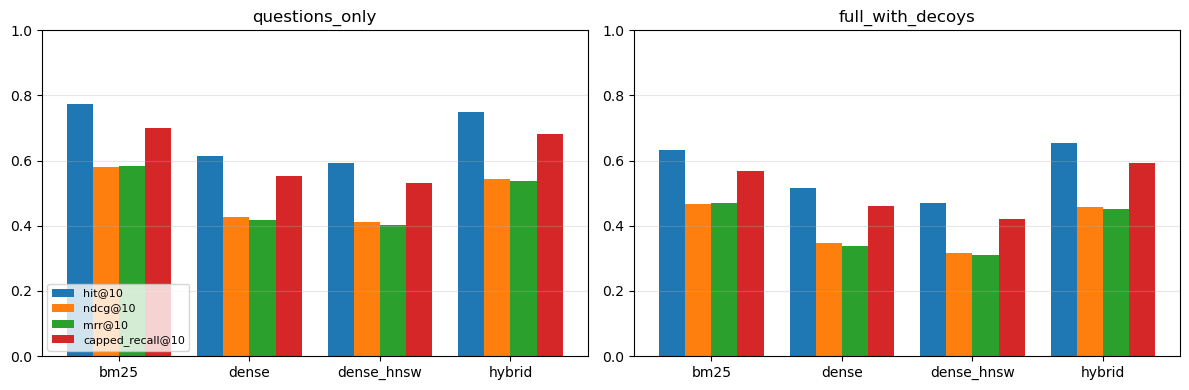

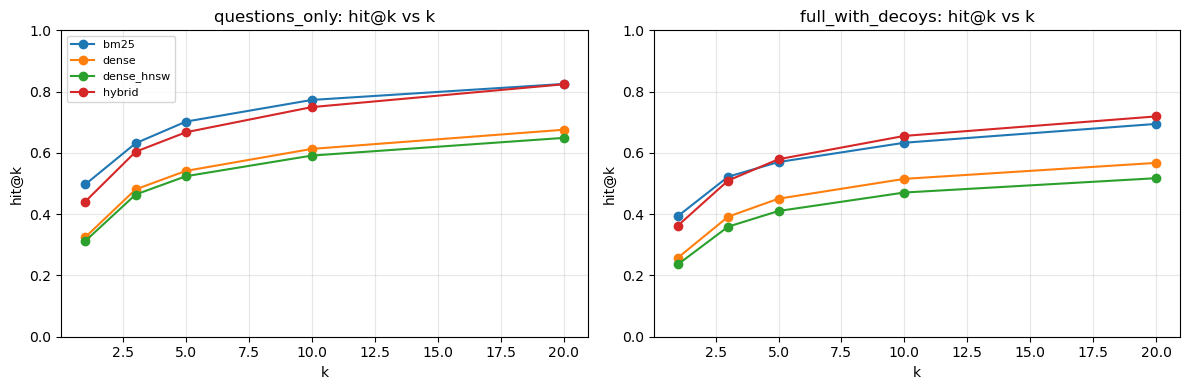

In [11]:
fig, axes = plt.subplots(1, len(SETTINGS), figsize=(6 * len(SETTINGS), 4), squeeze=False)
for ax, setting in zip(axes[0], SETTINGS):
    sub = HEADLINE.loc[setting]
    x = np.arange(len(sub))
    w = 0.2
    for j, col in enumerate([f"hit@{PK}", f"ndcg@{PK}", f"mrr@{PK}", f"capped_recall@{PK}"]):
        ax.bar(x + (j - 1.5) * w, sub[col], w, label=col)
    ax.set_xticks(x)
    ax.set_xticklabels(sub.index)
    ax.set_ylim(0, 1)
    ax.set_title(setting)
    ax.grid(axis="y", alpha=0.3)
axes[0][0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "headline.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, len(SETTINGS), figsize=(6 * len(SETTINGS), 4), squeeze=False)
for ax, setting in zip(axes[0], SETTINGS):
    for retr in GRID.loc[setting].index:
        ax.plot(KS, [GRID.loc[(setting, retr), f"hit@{k}"] for k in KS], marker="o", label=retr)
    ax.set_xlabel("k")
    ax.set_ylabel("hit@k")
    ax.set_ylim(0, 1)
    ax.set_title(f"{setting}: hit@k vs k")
    ax.grid(alpha=0.3)
axes[0][0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "hit_at_k.png", dpi=150)
plt.show()

## 6. Stability across repeated runs

For each retriever and corpus we compare every run against run 0:

* **identical_topk**: fraction of questions whose top k list is exactly the same in every run.
* **mean_jaccard_topk**: average overlap of the top k sets with run 0 (1.0 means the same chunks, possibly reordered).
* **hit_flip_rate**: fraction of questions whose Hit@k outcome changes in at least one run. This is the number that matters: a question that is answered in one run and missed in the next.
* **metric std across runs**: spread of the aggregate score. If this is larger than the gap between two retrievers, that gap is not real.
* **duplicate_query_consistency**: the question set contains repeated question strings; on a stable pipeline they must retrieve identical lists.

In [12]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0


norm_q = Q.question.map(norm).to_numpy()
dup_groups = [np.flatnonzero(norm_q == s) for s in pd.Series(norm_q).loc[lambda s: s.duplicated(keep=False)].unique()]

stab_rows = []
keys = list(RUNS[0].keys())
for key in keys:
    setting, retr = key
    lists = [RUNS[r][key] for r in range(len(RUNS))]
    n = len(lists[0])
    ident = np.mean([all(list(lists[r][i][:PK]) == list(lists[0][i][:PK]) for r in range(len(RUNS))) for i in range(n)])
    jac = np.mean([np.mean([jaccard(lists[r][i][:PK], lists[0][i][:PK]) for r in range(1, len(RUNS))]) for i in range(n)]) if len(RUNS) > 1 else 1.0
    sub = PQ[(PQ.setting == setting) & (PQ.retriever == retr) & (PQ.relevance == "chunk_id")]
    hits = sub.pivot(index="qi", columns="run", values=f"hit@{PK}")
    flip = float((hits.nunique(axis=1) > 1).mean())
    per_run = sub.groupby("run")[[PM, f"hit@{PK}", f"mrr@{PK}"]].mean()
    dup_ok = np.mean([all(list(lists[0][g[0]][:PK]) == list(lists[0][j][:PK]) for j in g) for g in dup_groups]) if dup_groups else np.nan
    stab_rows.append({
        "setting": setting,
        "retriever": retr,
        "runs": len(RUNS),
        f"identical_top{PK}": ident,
        f"mean_jaccard_top{PK}": jac,
        "hit_flip_rate": flip,
        f"{PM} mean": per_run[PM].mean(),
        f"{PM} std": per_run[PM].std(ddof=0),
        f"{PM} min": per_run[PM].min(),
        f"{PM} max": per_run[PM].max(),
        f"hit@{PK} std": per_run[f"hit@{PK}"].std(ddof=0),
        "duplicate_query_consistency": dup_ok,
        "mean_search_s": np.mean([t.get(key, np.nan) for t in TIMINGS]),
    })
STABILITY = pd.DataFrame(stab_rows).set_index(["setting", "retriever"])
display(STABILITY.round(5))
if "query_encode" in TIMINGS[0]:
    print("mean query encode time per run: %.2fs" % np.mean([t["query_encode"] for t in TIMINGS]))

runs  identical_top10  mean_jaccard_top10  hit_flip_rate  ndcg@10 mean  ndcg@10 std  ndcg@10 min  ndcg@10 max  hit@10 std  duplicate_query_consistency  mean_search_s
setting          retriever                                                                                                                                                                        
questions_only   bm25           5          1.00000             1.00000            0.0       0.58076          0.0      0.58076      0.58076         0.0                          1.0        0.26915
                 dense          5          0.99946             1.00000            0.0       0.42682          0.0      0.42682      0.42682         0.0                          1.0        0.03544
                 dense_hnsw     5          1.00000             1.00000            0.0       0.41157          0.0      0.41157      0.41157         0.0                          1.0        0.12235
                 hybrid         5          1.00000             1.00000            0.0       0.54372          0.0      0.54372      0.54372         0.0                          1.0        0.16178
full_with_decoys bm25           5          1.00000             1.00000            0.0       0.46632          0.0      0.46632      0.46632         0.0                          1.0        1.73222
                 dense          5          0.99783             0.99983            0.0       0.34799          0.0      0.34799      0.34799         0.0                          1.0        0.28746
                 dense_hnsw     5          1.00000             1.00000            0.0       0.31782          0.0      0.31782      0.31782         0.0                          1.0        3.64577
                 hybrid         5          0.99891             0.99995            0.0       0.45913          0.0      0.45913      0.45913         0.0                          1.0        0.16993

mean query encode time per run: 2.03s


In [13]:
if "dense_hnsw" in CONFIG["retrievers"] and "dense" in CONFIG["retrievers"]:
    ann_rows = []
    for setting in SETTINGS:
        for r in range(len(RUNS)):
            exact = RUNS[r][(setting, "dense")]
            approx = RUNS[r][(setting, "dense_hnsw")]
            ann_rows.append({
                "setting": setting,
                "run": r,
                f"ann_recall_vs_exact@{PK}": np.mean([len(set(a[:PK]) & set(e[:PK])) / PK for a, e in zip(approx, exact)]),
            })
    ANN = pd.DataFrame(ann_rows).groupby("setting")[f"ann_recall_vs_exact@{PK}"].agg(["mean", "std", "min", "max"])
    print("How much of the exact dense top k does the approximate index return?")
    display(ANN.round(5))

How much of the exact dense top k does the approximate index return?


,mean,std,min,max
setting,,,,
full_with_decoys,0.88354,0.00002,0.88353,0.88359
questions_only,0.96603,0.00000,0.96603,0.96603


## 7. Scaling: does the score hold with more questions?

From run 0, we draw random subsets of 50, 100, 250, 500, 1000 and all questions, many times each, and record the mean score of each draw. The spread of those means is the uncertainty you would have if the benchmark only had that many questions. The last table converts the per question standard deviation into the number of questions needed for a given margin of error at 95% confidence: n = (1.96 × sd / margin)².

In [14]:
rs = np.random.RandomState(CONFIG["seed"])
scale_rows = []
base = PQ[(PQ.run == 0) & (PQ.relevance == "chunk_id")]
for (setting, retr), sub in base.groupby(["setting", "retriever"]):
    v = sub.sort_values("qi")[PM].to_numpy()
    h = sub.sort_values("qi")[f"hit@{PK}"].to_numpy()
    N = len(v)
    for size in CONFIG["sample_sizes"]:
        n = N if size is None else size
        if n > N:
            continue
        draws = 1 if n == N else CONFIG["samples_per_size"]
        means, hmeans = [], []
        for _ in range(draws):
            ix = rs.choice(N, size=n, replace=False)
            means.append(np.nanmean(v[ix]))
            hmeans.append(h[ix].mean())
        means = np.asarray(means)
        scale_rows.append({
            "setting": setting, "retriever": retr, "n_questions": n, "draws": draws,
            f"{PM} mean": means.mean(), f"{PM} std": means.std(),
            "p2.5": np.percentile(means, 2.5), "p97.5": np.percentile(means, 97.5),
            "range_95": np.percentile(means, 97.5) - np.percentile(means, 2.5),
            f"hit@{PK} std": np.std(hmeans),
        })
SCALING = pd.DataFrame(scale_rows).set_index(["setting", "retriever", "n_questions"])
display(SCALING.round(4))

need_rows = []
for (setting, retr), sub in base.groupby(["setting", "retriever"]):
    sd = sub[PM].std()
    row = {"setting": setting, "retriever": retr, "per_question_sd": sd, "questions_available": len(sub)}
    for m in CONFIG["margins"]:
        row[f"n_for_±{m}"] = int(math.ceil((1.96 * sd / m) ** 2))
    need_rows.append(row)
NEEDED = pd.DataFrame(need_rows).set_index(["setting", "retriever"])
display(NEEDED.round(4))

draws  ndcg@10 mean  ndcg@10 std    p2.5   p97.5  range_95  hit@10 std
setting          retriever  n_questions                                                                        
full_with_decoys bm25       50             200        0.4708       0.0609  0.3660  0.5926    0.2266      0.0645
                            100            200        0.4591       0.0420  0.3818  0.5434    0.1616      0.0470
                            250            200        0.4637       0.0244  0.4123  0.5106    0.0983      0.0267
                            500            200        0.4657       0.0154  0.4343  0.4968    0.0625      0.0177
                            1000           200        0.4658       0.0095  0.4489  0.4849    0.0361      0.0105
                            1840             1        0.4663       0.0000  0.4663  0.4663    0.0000      0.0000
                 dense      50             200        0.3464       0.0542  0.2557  0.4596    0.2039      0.0659
                            100            200        0.3517       0.0364  0.2794  0.4215    0.1421      0.0473
                            250            200        0.3477       0.0227  0.3013  0.3894    0.0881      0.0285
                            500            200        0.3490       0.0146  0.3246  0.3776    0.0530      0.0178
                            1000           200        0.3481       0.0084  0.3339  0.3649    0.0310      0.0107
                            1840             1        0.3480       0.0000  0.3480  0.3480    0.0000      0.0000
                 dense_hnsw 50             200        0.3189       0.0560  0.2124  0.4366    0.2241      0.0677
                            100            200        0.3160       0.0397  0.2533  0.4144    0.1611      0.0503
                            250            200        0.3164       0.0248  0.2722  0.3683    0.0961      0.0301
                            500            200        0.3189       0.0139  0.2937  0.3450    0.0513      0.0180
                            1000           200        0.3186       0.0083  0.3039  0.3346    0.0308      0.0103
                            1840             1        0.3178       0.0000  0.3178  0.3178    0.0000      0.0000
                 hybrid     50             200        0.4628       0.0512  0.3572  0.5582    0.2010      0.0605
                            100            200        0.4586       0.0429  0.3758  0.5366    0.1608      0.0482
                            250            200        0.4597       0.0224  0.4148  0.5023    0.0875      0.0270
                            500            200        0.4593       0.0157  0.4271  0.4870    0.0600      0.0186
                            1000           200        0.4579       0.0084  0.4404  0.4729    0.0325      0.0106
                            1840             1        0.4591       0.0000  0.4591  0.4591    0.0000      0.0000
questions_only   bm25       50             200        0.5824       0.0577  0.4838  0.7095    0.2257      0.0590
                            100            200        0.5780       0.0392  0.5029  0.6486    0.1457      0.0414
                            250            200        0.5800       0.0236  0.5345  0.6294    0.0949      0.0234
                            500            200        0.5787       0.0144  0.5512  0.6052    0.0540      0.0143
                            1000           200        0.5807       0.0084  0.5664  0.5995    0.0331      0.0087
                            1840             1        0.5808       0.0000  0.5808  0.5808    0.0000      0.0000
                 dense      50             200        0.4274       0.0543  0.3333  0.5395    0.2062      0.0659
                            100            200        0.4289       0.0360  0.3547  0.4886    0.1339      0.0475
                            250            200        0.4268       0.0223  0.3881  0.4653    0.0773      0.0269
                            500            200        0.4256       0.0143  0.4002  0.4519    0.0517      0.0168
         

per_question_sd  questions_available  n_for_±0.05  n_for_±0.02  n_for_±0.01
setting          retriever                                                                              
full_with_decoys bm25                 0.4251                 1840          278         1736         6942
                 dense                0.3981                 1840          244         1523         6090
                 dense_hnsw           0.3928                 1840          238         1482         5928
                 hybrid               0.4087                 1840          257         1605         6417
questions_only   bm25                 0.4054                 1840          253         1579         6316
                 dense                0.4091                 1840          258         1608         6430
                 dense_hnsw           0.4089                 1840          257         1606         6424
                 hybrid               0.4013                 1840          248         1547         6187

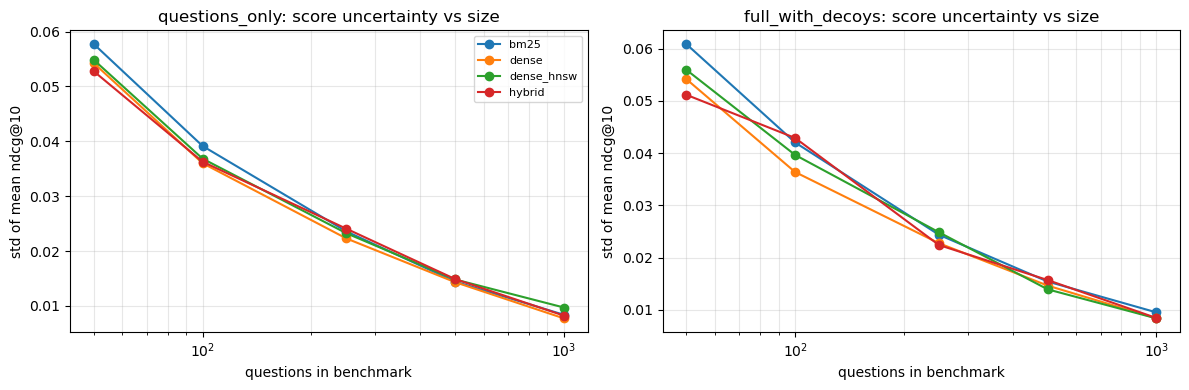

In [15]:
fig, axes = plt.subplots(1, len(SETTINGS), figsize=(6 * len(SETTINGS), 4), squeeze=False)
for ax, setting in zip(axes[0], SETTINGS):
    sub = SCALING.loc[setting].reset_index()
    for retr, g in sub.groupby("retriever"):
        g = g[g.draws > 1]
        ax.plot(g.n_questions, g[f"{PM} std"], marker="o", label=retr)
    ax.set_xscale("log")
    ax.set_xlabel("questions in benchmark")
    ax.set_ylabel(f"std of mean {PM}")
    ax.set_title(f"{setting}: score uncertainty vs size")
    ax.grid(alpha=0.3, which="both")
axes[0][0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "scaling.png", dpi=150)
plt.show()

## 8. Is one retriever really better? Paired bootstrap

Retrievers are scored on the same questions, so the right test is paired: resample questions, recompute the difference in the primary metric, and look at its confidence interval. If the interval crosses zero, the difference is not established on this benchmark.

In [16]:
pair_rows = []
rs = np.random.RandomState(CONFIG["seed"])
for setting in SETTINGS:
    wide = base[base.setting == setting].pivot(index="qi", columns="retriever", values=PM)
    for a, b in combinations(wide.columns, 2):
        d = (wide[a] - wide[b]).dropna().to_numpy()
        means = d[rs.randint(0, d.size, size=(CONFIG["bootstrap_iters"], d.size))].mean(axis=1)
        lo, hi = np.percentile(means, [2.5, 97.5])
        pair_rows.append({
            "setting": setting, "a": a, "b": b,
            f"mean({PM} a minus b)": d.mean(), "ci_low": lo, "ci_high": hi,
            "a_wins": int((d > 0).sum()), "b_wins": int((d < 0).sum()), "ties": int((d == 0).sum()),
            "significant": bool(lo > 0 or hi < 0),
        })
PAIRS = pd.DataFrame(pair_rows)
display(PAIRS.round(4))

,setting,a,b,mean(ndcg@10 a minus b),ci_low,ci_high,a_wins,b_wins,ties,significant
0,questions_only,bm25,dense,0.1539,0.1350,0.1734,765,346,729,True
1,questions_only,bm25,dense_hnsw,0.1692,0.1494,0.1895,794,330,716,True
2,questions_only,bm25,hybrid,0.0370,0.0235,0.0513,465,424,951,True
3,questions_only,dense,dense_hnsw,0.0153,0.0102,0.0209,42,25,1773,True
4,questions_only,dense,hybrid,-0.1169,-0.1296,-0.1045,174,726,940,True
5,questions_only,dense_hnsw,hybrid,-0.1322,-0.1452,-0.1199,171,749,920,True
6,full_with_decoys,bm25,dense,0.1183,0.0979,0.1373,664,348,828,True
7,full_with_decoys,bm25,dense_hnsw,0.1485,0.1284,0.1682,703,333,804,True
8,full_with_decoys,bm25,hybrid,0.0072,-0.0059,0.0201,391,403,1046,False
9,full_with_decoys,dense,dense_hnsw,0.0302,0.0230,0.0375,88,48,1704,True


## 9. Where it breaks

* **Decoy damage**: how much each retriever loses when 1,500 topic matched decoy papers are added.
* **By match type** (`exact`, `fuzzy`): fuzzy gold spans are harder to locate.
* **By gold chunk count**: single gold chunk questions are the strictest test.
* **Diagnostic quadrant** from Session 1: a miss means retrieval is broken (fix the embedder, index or chunking); a hit at a low rank means ranking is weak (add a reranker); a hit in the top 3 is healthy.

In [17]:
if len(SETTINGS) == 2:
    dd = HEADLINE[[PM, f"hit@{PK}", f"mrr@{PK}"]].unstack("setting")
    damage = pd.DataFrame({
        f"{PM} questions_only": dd[(PM, "questions_only")],
        f"{PM} full_with_decoys": dd[(PM, "full_with_decoys")],
        f"{PM} drop": dd[(PM, "questions_only")] - dd[(PM, "full_with_decoys")],
        f"hit@{PK} drop": dd[(f"hit@{PK}", "questions_only")] - dd[(f"hit@{PK}", "full_with_decoys")],
    })
    damage[f"{PM} relative drop %"] = 100 * damage[f"{PM} drop"] / damage[f"{PM} questions_only"]
    print("Decoy damage")
    display(damage.round(4))

    paper_hits = base.copy()
    paper_hits["top1_paper_ok"] = [
        CHUNK_PAPER[RUNS[0][(s, r)][qi][0]] == p
        for s, r, qi, p in zip(paper_hits.setting, paper_hits.retriever, paper_hits.qi, paper_hits.paper)
    ]
    print("Top 1 chunk comes from the correct paper")
    display(paper_hits.groupby(["setting", "retriever"]).top1_paper_ok.mean().unstack("setting").round(4))

print("By match type")
display(base.groupby(["setting", "retriever", "match"])[[PM, f"hit@{PK}"]].mean().unstack("match").round(4))
print("By number of gold chunks")
display(base.groupby(["setting", "retriever", "gold_bucket"], observed=True)[[PM, f"hit@{PK}"]].mean().unstack("gold_bucket").round(4))


def bucket(row):
    if row[f"hit@{PK}"] == 0:
        return "missed"
    return "hit, rank 1 to 3" if row["first_rank"] <= 3 else f"hit, rank 4 to {PK}"


diag = base.assign(diagnosis=base.apply(bucket, axis=1))
QUAD = diag.groupby(["setting", "retriever"]).diagnosis.value_counts(normalize=True).unstack().fillna(0)
print("Diagnostic quadrant")
display(QUAD.round(4))

Decoy damage


,ndcg@10 questions_only,ndcg@10 full_with_decoys,ndcg@10 drop,hit@10 drop,ndcg@10 relative drop %
retriever,,,,,
bm25,0.5808,0.4663,0.1144,0.1397,19.7059
dense,0.4268,0.3480,0.0788,0.0978,18.4702
dense_hnsw,0.4116,0.3178,0.0937,0.1207,22.7769
hybrid,0.5437,0.4591,0.0846,0.0940,15.5583


Top 1 chunk comes from the correct paper


setting,full_with_decoys,questions_only
retriever,,
bm25,0.5293,0.6620
dense,0.4380,0.5527
dense_hnsw,0.4065,0.5359
hybrid,0.5239,0.6446


By match type


ndcg@10          hit@10        
match                         exact   fuzzy   exact   fuzzy
setting          retriever                                 
full_with_decoys bm25        0.4687  0.4228  0.6388  0.5312
                 dense       0.3507  0.2987  0.5201  0.4271
                 dense_hnsw  0.3204  0.2717  0.4753  0.3854
                 hybrid      0.4624  0.3994  0.6628  0.5208
questions_only   bm25        0.5822  0.5547  0.7787  0.6667
                 dense       0.4288  0.3916  0.6170  0.5417
                 dense_hnsw  0.4139  0.3688  0.5958  0.5104
                 hybrid      0.5467  0.4890  0.7546  0.6562

By number of gold chunks


ndcg@10                  hit@10                
gold_bucket                       1  2 to 5      6+       1  2 to 5      6+
setting          retriever                                                 
full_with_decoys bm25        0.4955  0.3475  0.2525  0.6172  0.7151  0.7232
                 dense       0.3639  0.2835  0.2315  0.4958  0.5754  0.6875
                 dense_hnsw  0.3308  0.2656  0.2225  0.4500  0.5363  0.6518
                 hybrid      0.4840  0.3595  0.2744  0.6430  0.7095  0.7411
questions_only   bm25        0.6160  0.4462  0.3089  0.7586  0.8492  0.8482
                 dense       0.4465  0.3420  0.2902  0.5920  0.6704  0.8125
                 dense_hnsw  0.4291  0.3389  0.2856  0.5694  0.6592  0.7857
                 hybrid      0.5713  0.4317  0.3411  0.7347  0.8156  0.8482

Diagnostic quadrant


diagnosis                    hit, rank 1 to 3  hit, rank 4 to 10  missed
setting          retriever                                              
full_with_decoys bm25                  0.5223             0.1109  0.3668
                 dense                 0.3918             0.1234  0.4848
                 dense_hnsw            0.3592             0.1114  0.5293
                 hybrid                0.5098             0.1457  0.3446
questions_only   bm25                  0.6315             0.1413  0.2272
                 dense                 0.4810             0.1321  0.3870
                 dense_hnsw            0.4641             0.1272  0.4087
                 hybrid                0.6038             0.1457  0.2505

In [18]:
hard = list(SETTINGS)[-1]
hard_base = base[base.setting == hard]
missed_all = hard_base.groupby("qi")[f"hit@{PK}"].max()
missed_all = missed_all[missed_all == 0].index
lead = HEADLINE.loc[hard][PM].idxmax()
print(f"{len(missed_all)} questions missed by every retriever in '{hard}' at k={PK}. Examples using '{lead}':")
ex = []
for qi in list(missed_all)[:10]:
    top = RUNS[0][(hard, lead)][qi][0]
    ex.append({
        "question": Q.question[qi],
        "gold_answer": Q.answer[qi],
        "gold_paper": Q.paper[qi],
        "n_gold": Q.n_gold[qi],
        "top1_paper": CHUNK_PAPER[top],
        "top1_snippet": chunks.text.iat[top][:200].replace("\n", " "),
    })
FAILURES = pd.DataFrame(ex)
display(FAILURES)

481 questions missed by every retriever in 'full_with_decoys' at k=10. Examples using 'bm25':


,question,gold_answer,gold_paper,n_gold,top1_paper,top1_snippet
0,What health regulations were changes due to the outbreak of C. burnetti?,forbid the display of sheep in the latter third of their pregnancy and require regular testing of animals for C. bur...,pmc1618839,1,pmc7026896,This outbreak and the response to it illustrate some key issues about how global preparedness and response capacity ...
1,What important risk factors to infection were found during the second case-controlled study?,close proximity to the ewe and duration of exposure,pmc1618839,1,pmc7737123,Male gender and older age were found to be significantly associated with SARS-CoV-2 infection. Although male gender ...
2,What was the purpose of this study?,to assess the evolutionary history of lion,pmc2572142,1,pmc7241223,"the nose (correct). What is the purpose of the metal strip on a surgical, 117 = 361. What is the purpose of the meta..."
3,What was the goal of this study?,to explore the feasibility of DNA vaccination of poultry,pmc2657001,1,pmc7538634,- -The Problem: The continuous sense of anxiety generated by the coronavirus emergency can lead to the halting of ou...
4,What is the conclusion of this study?,it is possible to develop a multivalent DNA vaccine for poultry that can protect against multiple HPAI H5N1 strains ...,pmc2657001,1,pmc7887205,"In conclusion, the study established a rapid screening model for predicting NCP in a Zhejiang population. What's mor..."
5,What is lipopolysaccharide?,a cell wall component of Gram-negative bacteria,pmc2804704,1,pmc7315394,"- [254] Y. Zhang, B. Chi-Yan Cheng, R. Xie, B. Xu, X. Y. Gao, and G. Luo, ' Re-Du-Ninginhalation solution exerts sup..."
6,Is there a treatment?,"Currently, there is no vaccine or antiviral treatmen",pmc2860491,1,pmc7677234,"were used, and not different to those found in the mock-treated cells ( Table 3A ). Likewise, no changes in cell siz..."
7,What conclusion is drawn in this report?,"With the threat of an emerging global pandemic, the peculiar problems associated with the more immediate and seasona...",pmc2860491,1,pmc8424738,Qr code Scan this QR code with your smart phone or mobile device to read online. Scan this QR code with your smart p...
8,In the epidemic peak how many cases per week were there on the island?,"46,000",pmc2860491,1,pmc7402809,"This paper highlights the changes to COVID-19 control measure variables to estimate the time to the peak of cases, w..."
9,What does this review detail?,the epidemiology and global expansion of CHIKV,pmc2860491,1,pmc7702164,- The dosed of medications that she used in OPD should be provided in the part of the case report. 1. - The author s...


## 10. Findings

The cell below writes the conclusions directly from the numbers above, so it stays correct when the configuration, model or dataset version changes.

In [19]:
lines = []
for setting in SETTINGS:
    h = HEADLINE.loc[setting]
    best = h[PM].idxmax()
    lines.append(
        f"[{setting}] best retriever is {best}: {PM} = {h.loc[best, PM]:.3f} "
        f"(95% CI {h.loc[best, f'{PM} ci_low']:.3f} to {h.loc[best, f'{PM} ci_high']:.3f}), "
        f"hit@{PK} = {h.loc[best, f'hit@{PK}']:.3f}, mrr@{PK} = {h.loc[best, f'mrr@{PK}']:.3f}."
    )
    for retr in h.index:
        if retr == best:
            continue
        p = PAIRS[(PAIRS.setting == setting) & (((PAIRS.a == best) & (PAIRS.b == retr)) | ((PAIRS.a == retr) & (PAIRS.b == best)))]
        if len(p):
            p = p.iloc[0]
            verdict = "a real difference" if p.significant else "not a significant difference"
            lines.append(f"    vs {retr}: {PM} {h.loc[retr, PM]:.3f}, {verdict} (paired CI {p.ci_low:+.3f} to {p.ci_high:+.3f} for {p.a} minus {p.b}).")
    q = QUAD.loc[setting].loc[best]
    lines.append(f"    diagnosis for {best}: {q.get('missed', 0):.1%} missed, {q.get(f'hit, rank 4 to {PK}', 0):.1%} found low, {q.get('hit, rank 1 to 3', 0):.1%} found in top 3.")

if len(SETTINGS) == 2:
    for retr, row in damage.iterrows():
        lines.append(f"[decoys] {retr} loses {row[f'{PM} drop']:.3f} {PM} ({row[f'{PM} relative drop %']:.1f}%) when decoy papers are added.")

for (setting, retr), row in STABILITY.iterrows():
    stable = row[f"identical_top{PK}"] == 1.0 and row["hit_flip_rate"] == 0.0
    tag = "fully deterministic" if stable else "NOT deterministic"
    lines.append(
        f"[stability] {setting}/{retr}: {tag} over {int(row['runs'])} runs; identical top {PK} for {row[f'identical_top{PK}']:.1%} of questions, "
        f"hit flips on {row['hit_flip_rate']:.2%}, {PM} std across runs {row[f'{PM} std']:.5f}."
    )

for (setting, retr), row in NEEDED.iterrows():
    m = CONFIG["margins"]
    lines.append(
        f"[size] {setting}/{retr}: {int(row['questions_available'])} questions available; "
        + ", ".join(f"±{x} needs {int(row[f'n_for_±{x}'])}" for x in m) + "."
    )

FINDINGS = "\n".join(lines)
print(FINDINGS)

[questions_only] best retriever is bm25: ndcg@10 = 0.581 (95% CI 0.562 to 0.599), hit@10 = 0.773, mrr@10 = 0.583.
    vs dense: ndcg@10 0.427, a real difference (paired CI +0.135 to +0.173 for bm25 minus dense).
    vs dense_hnsw: ndcg@10 0.412, a real difference (paired CI +0.149 to +0.190 for bm25 minus dense_hnsw).
    vs hybrid: ndcg@10 0.544, a real difference (paired CI +0.023 to +0.051 for bm25 minus hybrid).
    diagnosis for bm25: 22.7% missed, 14.1% found low, 63.2% found in top 3.
[full_with_decoys] best retriever is bm25: ndcg@10 = 0.466 (95% CI 0.447 to 0.485), hit@10 = 0.633, mrr@10 = 0.470.
    vs dense: ndcg@10 0.348, a real difference (paired CI +0.098 to +0.137 for bm25 minus dense).
    vs dense_hnsw: ndcg@10 0.318, a real difference (paired CI +0.128 to +0.168 for bm25 minus dense_hnsw).
    vs hybrid: ndcg@10 0.459, not a significant difference (paired CI -0.006 to +0.020 for bm25 minus hybrid).
    diagnosis for bm25: 36.7% missed, 11.1% found low, 52.2% found in 

## 11. Save everything

All tables, plots, per question scores, the exact configuration, library versions and data file hashes go to `results/`, so any number in this notebook can be traced and reproduced.

In [20]:
def versions():
    out = {"python": sys.version.split()[0], "platform": platform.platform(), "device": DEVICE}
    for mod in ["numpy", "pandas", "bm25s", "faiss", "sentence_transformers", "torch", "transformers"]:
        try:
            out[mod] = __import__(mod).__version__
        except Exception:
            out[mod] = None
    return out


HEADLINE.to_csv(RESULTS / "headline.csv")
GRID.to_csv(RESULTS / "metric_grid.csv")
STABILITY.to_csv(RESULTS / "stability.csv")
SCALING.to_csv(RESULTS / "scaling.csv")
NEEDED.to_csv(RESULTS / "questions_needed.csv")
PAIRS.to_csv(RESULTS / "paired_bootstrap.csv", index=False)
QUAD.to_csv(RESULTS / "diagnosis.csv")
FAILURES.to_csv(RESULTS / "failures.csv", index=False)
PQ.to_csv(RESULTS / "per_query.csv.gz", index=False, compression="gzip")
EXCLUDED[["qid", "paper", "match", "question", "answer"]].to_csv(RESULTS / "excluded_questions.csv", index=False)
(RESULTS / "findings.txt").write_text(FINDINGS + "\n", encoding="utf-8")
meta = {
    "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S%z"),
    "config": CONFIG,
    "data_hash": DATA_HASH,
    "audit": audit,
    "scorable_questions": len(Q),
    "versions": versions(),
}
(RESULTS / "run_meta.json").write_text(json.dumps(meta, indent=2, default=str), encoding="utf-8")
print("saved:", sorted(p.name for p in RESULTS.iterdir()))

saved: ['diagnosis.csv', 'excluded_questions.csv', 'failures.csv', 'findings.txt', 'headline.csv', 'headline.png', 'hit_at_k.png', 'metric_grid.csv', 'paired_bootstrap.csv', 'per_query.csv.gz', 'questions_needed.csv', 'run_meta.json', 'scaling.csv', 'scaling.png', 'stability.csv']
